Vamos a trabajar con el siguiente Dataset:

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Preparación del Dataset desbalanceado (90% negativos, 10% positivos)
X, y = make_classification(
    n_samples=1000, n_features=10, weights=[0.9, 0.1], random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Visualizá la proporción de datos que pertenecen a cada clase (0, 1).

(0.0, 1000.0)

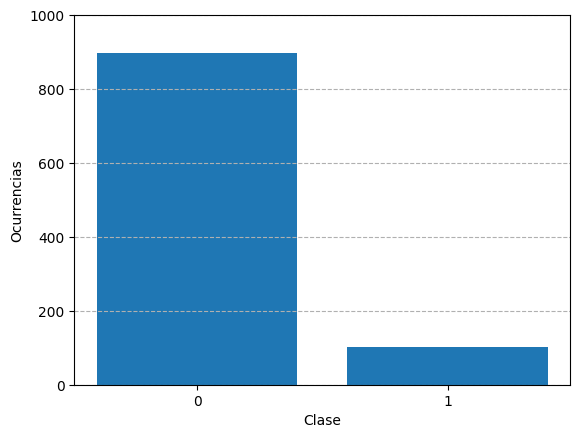

In [9]:
from collections import Counter

count = Counter(y)

plt.bar(count.keys(), count.values())
plt.grid(axis='y', linestyle='--')
plt.xlabel('Clase')
plt.ylabel('Ocurrencias')
plt.xticks([0, 1])
plt.ylim(0, 1000)

**Entrená un modelo ingenuo.** Utilizá DummyClassifier(strategy='most_frequent') ([Documentación de Dummy Classifier](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html)) sobre el conjunto de entrenamiento para predecir siempre la clase mayoritaria.

In [10]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

Evaluá la precisión global del modelo con `accuracy_score`. Explicá por qué un accuracy alto no significa que el modelo sea útil para este caso.

In [11]:
acc_dummy = accuracy_score(y_test, y_pred_dummy)
print(f"Accuracy del modelo Dummy: {acc_dummy:.4f}")

# El modelo alcanza casi un 90% de accuracy simplemente prediciendo siempre la clase 0.
# Sin embargo, es inútil porque detecta el 0% de los casos positivos reales (clase 1).

Accuracy del modelo Dummy: 0.8950


Graficá la matriz utilizando `ConfusionMatrixDisplay.from_estimator()` de Scikit-Learn.

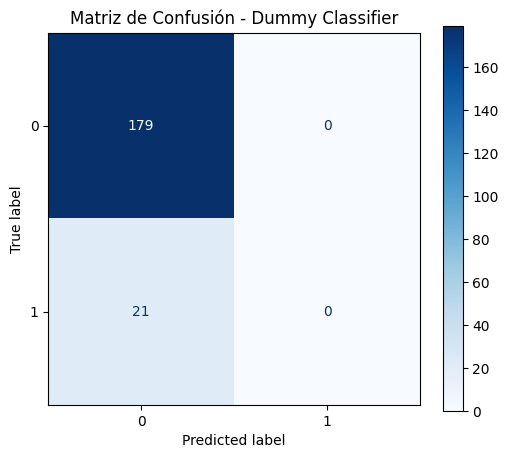

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    dummy, X_test, y_test, cmap="Blues", ax=ax
)
plt.title("Matriz de Confusión - Dummy Classifier")
plt.show()

Extraé e imprimí en pantalla los valores de Verdaderos Positivos ($TP$), Verdaderos Negativos ($TN$), Falsos Positivos ($FP$) y Falsos Negativos ($FN$) a partir de la matriz.

In [13]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_dummy).ravel()
print(
    f"Verdaderos Negativos (TN): {tn} | Falsos Positivos (FP): {fp}"
)  # TN: 179, FP: 0
print(
    f"Falsos Negativos (FN): {fn} | Verdaderos Positivos (TP): {tp}"
)  # FN: 21,  TP: 0

Verdaderos Negativos (TN): 179 | Falsos Positivos (FP): 0
Falsos Negativos (FN): 21 | Verdaderos Positivos (TP): 0


Ahora entrená un modelo de clasificación real. Instanciá y entrená un modelo (Por ejemplo, [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), recordando que todos los modelos se entrenan y evalúan igual) con el dataset proporcionado.

In [32]:
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Usá `classification_report` para observar los valores iniciales de Precision, Recall y F1-Score con el umbral por defecto (0.5).

In [33]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.97      0.96       179
           1       0.67      0.48      0.56        21

    accuracy                           0.92       200
   macro avg       0.80      0.72      0.76       200
weighted avg       0.91      0.92      0.91       200



Usá el método `predict_proba()` sobre el conjunto de test para extraer la probabilidad predicha para la clase positiva.

In [34]:
y_probs = model.predict_proba(X_test)[:, 1]

Armá un bucle `for` que varíe el umbral de decisión desde 0.1 hasta 0.9 con pasos de 0.05. Para cada umbral, reclasificá las probabilidades ($1$ si $prob \ge threshold$, de lo contrario $0$) y calculá Precision, Recall y F1-Score. Construí un gráfico en Matplotlib con las curvas de Precision, Recall y F1-Score en función del umbral de decisión.

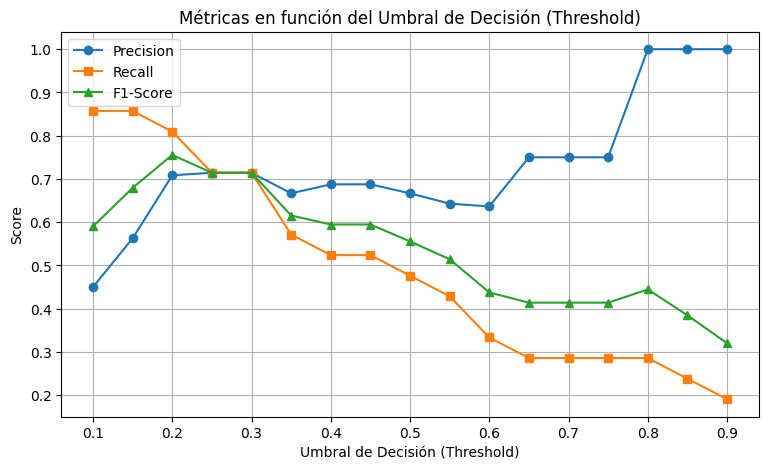

In [35]:
thresholds = np.arange(0.1, 0.95, 0.05)
precisions, recalls, f1s = [], [], []

for t in thresholds:
  y_pred_t = (y_probs >= t).astype(int)
  precisions.append(precision_score(y_test, y_pred_t, zero_division=0))
  recalls.append(recall_score(y_test, y_pred_t, zero_division=0))
  f1s.append(f1_score(y_test, y_pred_t, zero_division=0))

# Graficar en Matplotlib
plt.figure(figsize=(9, 5))
plt.plot(thresholds, precisions, label="Precision", marker="o")
plt.plot(thresholds, recalls, label="Recall", marker="s")
plt.plot(thresholds, f1s, label="F1-Score", marker="^")
plt.title("Métricas en función del Umbral de Decisión (Threshold)")
plt.xlabel("Umbral de Decisión (Threshold)")
plt.ylabel("Score")
plt.grid(True)
plt.legend()
plt.show()

Analizá el gráfico y elegí qué umbral utilizarías si la prioridad absoluta del problema fuera minimizar los Falsos Negativos.

In [ ]:
# Para minimizar los Falsos Negativos ($FN$) y maximizar el Recall,
# conviene bajar el umbral a un valor cercano a 0.20. Con ese umbral,
# el modelo captura la mayor cantidad de casos positivos reales a costa
# de tolerar algunos Falsos Positivos ($FP$).

Usá la función `roc_curve` pasándole los valores reales y las probabilidades predichas para obtener la tasa de Falsos Positivos ($FPR$) y la tasa de Verdaderos Positivos ($TPR$).

In [36]:
fpr_log, tpr_log, _ = roc_curve(y_test, y_probs)

Dibujá la curva $FPR$ vs. $TPR$ en Matplotlib e incluí la línea diagonal discontinua de referencia que representa un clasificador aleatorio. Medí el área bajo la curva con roc_auc_score e interpretá el resultado.

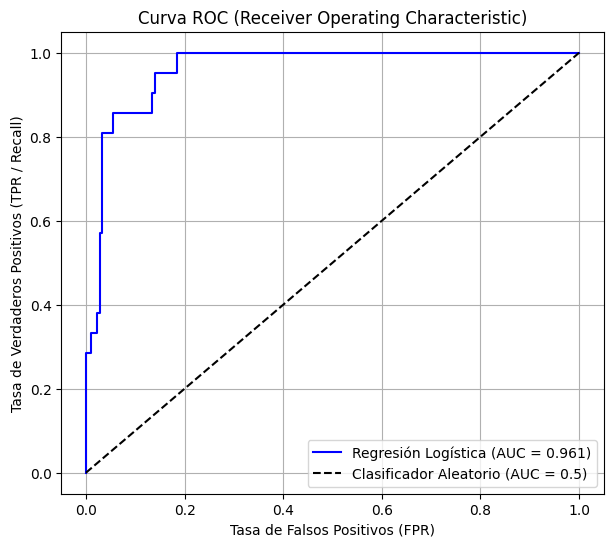

In [37]:
auc_log = roc_auc_score(y_test, y_probs)

plt.figure(figsize=(7, 6))
plt.plot(
    fpr_log,
    tpr_log,
    label=f"Regresión Logística (AUC = {auc_log:.3f})",
    color="blue",
)
plt.plot(
    [0, 1], [0, 1], "k--", label="Clasificador Aleatorio (AUC = 0.5)"
)  # Diagonal de referencia
plt.title("Curva ROC (Receiver Operating Characteristic)")
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR / Recall)")
plt.grid(True)
plt.legend()
plt.show()

Entrená un segundo modelo (Por ejemplo, DecisionTreeClassifier) con distinta configuración o algoritmo, graficá ambas curvas ROC en el mismo plano cartesiano y determiná visual y numéricamente cuál separa mejor las clases.

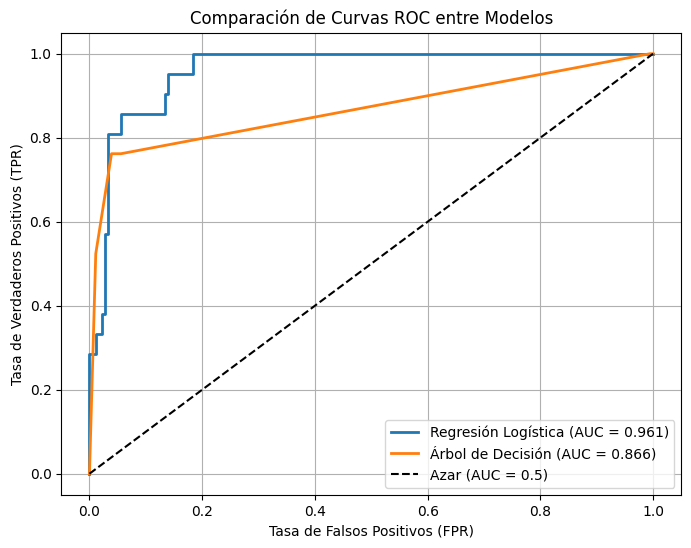

AUC Regresión Logística: 0.9606
AUC Árbol de Decisión: 0.8661


In [38]:
# Entrená un Árbol de Decisión como segundo modelo
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
tree_probs = tree.predict_proba(X_test)[:, 1]

# Calculá ROC y AUC para el Árbol
fpr_tree, tpr_tree, _ = roc_curve(y_test, tree_probs)
auc_tree = roc_auc_score(y_test, tree_probs)

# Graficá ambos modelos juntos
plt.figure(figsize=(8, 6))
plt.plot(
    fpr_log,
    tpr_log,
    label=f"Regresión Logística (AUC = {auc_log:.3f})",
    linewidth=2,
)
plt.plot(
    fpr_tree,
    tpr_tree,
    label=f"Árbol de Decisión (AUC = {auc_tree:.3f})",
    linewidth=2,
)
plt.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")
plt.title("Comparación de Curvas ROC entre Modelos")
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.grid(True)
plt.legend()
plt.show()

print(f"AUC Regresión Logística: {auc_log:.4f}")
print(f"AUC Árbol de Decisión: {auc_tree:.4f}")